# Notebook 2 — How Compass works: from a transcriptome to one number per reaction

**Goal:** after this notebook you can explain, in your own words and with working code, *what a Compass score is*. We do it in four steps, each verified against the repository's own numbers:

| Part | Question | Check |
|---|---|---|
| **A** | What is flux balance analysis (FBA) and what does Compass change? | a 7-reaction toy network you can solve by hand |
| **B** | How do genes become **penalties** (stage 1)? | our code vs the repo's code, on the real Th17 cells |
| **C** | How do penalties become **scores** (stage 2, the linear program)? | we re-solve real Compass LPs with an open-source solver and compare to the repo's `reactions.tsv` |
| **D** | What do the numbers *mean* — and what do they not? | facts computed from the files, tagged **[Inference]** when it is my reading |

Sources: the uploaded paper (**[Paper]**, STAR Methods "Brief review of GSMM definitions" and "The Compass algorithm in detail") and the Compass repository (**[Repo]**, file named). No Gurobi licence is needed — Compass itself needs one for large runs, but here we use SciPy's free HiGHS solver on a single LP at a time.

**Run time ≈ 1–2 min.** Requires the same packages as Notebook 1 (see `requirements.txt`).

## 0 · Setup
### 0.1 Imports, environment check, and locating the Compass clone
**Run the two cells below first — every time the kernel restarts** (everything later needs `pd`, `np`, `REPO`, `DATA`). In VS Code pick your `che411` environment as the kernel (top right of the notebook). The data live inside the Compass GitHub repo (`docs/notebooks/extdata/`).

**The only line you may need to edit is `REPO_PATH`** in the second cell. It also lists every file the notebook reads, with its size, so a wrong path or an incomplete clone is reported *here* with a fix, not 20 cells later.

In [ ]:
import os, sys, re, json, platform, subprocess, warnings, time
from pathlib import Path
from dataclasses import dataclass

try:
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import seaborn as sns
    from scipy import sparse, stats
    from scipy.optimize import linprog
    from sklearn.decomposition import PCA
    from sklearn.neighbors import NearestNeighbors
except ModuleNotFoundError as e:
    raise ModuleNotFoundError(
        f"The package '{e.name}' is not installed in the Python that runs this notebook:\n  {sys.executable}\n"
        "Fix: select your che411 environment as the kernel, OR in a terminal with che411 active run\n"
        "  python -m pip install -r requirements.txt\n"
        "then restart the kernel and run this cell again.") from None

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30, "display.width", 150, "display.precision", 4)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

# ---- environment check: lowest versions this notebook was written against (see requirements.txt) ----
from importlib.metadata import version, PackageNotFoundError
MIN_VERSIONS = {"numpy": "1.24", "pandas": "2.0", "scipy": "1.10", "scikit-learn": "1.2", "matplotlib": "3.7", "seaborn": "0.13"}
def _major_minor(v):
    return tuple(int(x) for x in re.findall(r"\d+", v)[:2])
print(f"Python {platform.python_version()}   |   this kernel runs: {sys.executable}")
too_old = []
for pkg, lowest in MIN_VERSIONS.items():
    try:
        have = version(pkg)
    except PackageNotFoundError:
        have = None
    ok = have is not None and _major_minor(have) >= _major_minor(lowest)
    print(f"  {'OK ' if ok else 'OLD'}  {pkg:<13} {have or 'unknown':<10} (needs >= {lowest})")
    if not ok:
        too_old.append(pkg)
if sys.version_info < (3, 10):
    print("! Python 3.10+ is recommended (the Compass repo itself requires it).")
if too_old:
    print("\n! Upgrade with:   python -m pip install -U " + " ".join(too_old) + "   then restart the kernel and re-run.")

In [ ]:
# =========================================================================================================
#  >>>  THE ONLY LINE YOU MAY NEED TO EDIT  <<<
#  The folder created by `git clone https://github.com/wagnerlab-berkeley/Compass.git`
#  (the one that contains README.md, compass/ and docs/).   macOS ignores letter case: ".../compass" also works.
REPO_PATH  = "/Users/willnath/Compass"
AUTO_CLONE = False          # True = if nothing is found, clone the repo into ./Compass (about 400 MB)
# =========================================================================================================

REPO_URL = "https://github.com/wagnerlab-berkeley/Compass.git"
MARKER   = "docs/notebooks/extdata/Th17/reactions.tsv"        # a file that exists only in the repo's top folder

def _is_repo(p):
    try:
        return (Path(p).expanduser() / MARKER).exists()
    except OSError:
        return False

def find_repo():
    """Return (repo_folder, how_it_was_found). Order: REPO_PATH, $COMPASS_REPO, this folder + parents, usual places."""
    cands = [("REPO_PATH", REPO_PATH), ("$COMPASS_REPO", os.environ.get("COMPASS_REPO"))]
    for up in [Path.cwd(), *Path.cwd().parents]:
        cands += [("the notebook's folder / a parent", up), ("a 'Compass' sub-folder", up / "Compass")]
    for sub in ["Compass", "compass", "Documents/Compass", "Documents/GitHub/Compass", "Desktop/Compass",
                "Downloads/Compass", "projects/Compass", "code/Compass", "GitHub/Compass"]:
        cands.append(("a usual place under your home folder", Path.home() / sub))
    for how, c in cands:
        if c and _is_repo(c):
            return Path(c).expanduser().resolve(), how
    return None, None

REPO, how_found = find_repo()
if REPO is None and AUTO_CLONE:
    print("Compass repo not found locally - cloning (shallow) into ./Compass ...")
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "Compass"], check=True)
    REPO, how_found = find_repo()
if REPO is None:
    raise FileNotFoundError(
        f"Could not find the Compass repository (looked for the file {MARKER}).\n"
        f"  REPO_PATH is currently '{REPO_PATH}'.\n"
        "  Fix 1: set REPO_PATH (above) to your clone. In a terminal:  cd <your clone>  and run  pwd  to print the path.\n"
        f"  Fix 2: not cloned yet?  git clone {REPO_URL}   (or set AUTO_CLONE = True)")
if how_found != "REPO_PATH":
    print(f"! REPO_PATH ('{REPO_PATH}') does not contain the repo; using the clone found via: {how_found}.\n")

DATA = REPO / "docs/notebooks/extdata"                         # Th17/ and RECON2/ live here
RES       = REPO / "compass/Resources"
MODEL_DIR = RES / "Metabolic Models/RECON2_mat"          # Recon2 in the repo's JSON export
PAL = {"Th17p": "#E92E87", "Th17n": "#348C73"}
# ---- every file this notebook reads (path relative to the repo folder -> what it is) ----
REQUIRED = {
    'docs/notebooks/extdata/Th17/linear_gene_expression_matrix.tsv': "gene x 290-cell TPM matrix = the paper's input (GEO GSE74833)",
    'docs/notebooks/extdata/Th17/cell_metadata.csv': 'per cell: Th17p / Th17n label',
    'docs/notebooks/extdata/Th17/reactions.tsv': 'Compass OUTPUT: penalty per reaction x cell (used to check our LPs)',
    'docs/notebooks/extdata/RECON2/reaction_metadata.csv': 'Recon2 reactions as a table',
    'compass/Resources/Metabolic Models/RECON2_mat/model/model.S.json': "Recon2 array 'S'",
    'compass/Resources/Metabolic Models/RECON2_mat/model/model.genes.json': "Recon2 array 'genes'",
    'compass/Resources/Metabolic Models/RECON2_mat/model/model.lb.json': "Recon2 array 'lb'",
    'compass/Resources/Metabolic Models/RECON2_mat/model/model.mets.json': "Recon2 array 'mets'",
    'compass/Resources/Metabolic Models/RECON2_mat/model/model.rules.json': "Recon2 array 'rules'",
    'compass/Resources/Metabolic Models/RECON2_mat/model/model.rxns.json': "Recon2 array 'rxns'",
    'compass/Resources/Metabolic Models/RECON2_mat/model/model.ub.json': "Recon2 array 'ub'",
    'compass/Resources/Metabolic Models/RECON2_mat/media/default-media.json': 'medium: exchange bounds',
    'compass/Resources/Metabolic Models/RECON2_mat/non2uniqueEntrez.json': 'gene id mapping',
    'compass/Resources/Metabolic Models/RECON2_mat/uniqueMouseGeneSymbol.json': 'mouse gene symbols',
    'compass/Resources/Metabolic Models/RECON2_mat/uniqueMouseGeneSymbol_all.json': 'mouse gene symbols (all)',
    'compass/Resources/COMPASS/RECON2_mat/default-media/preprocess.json': 'stage-0 v_opt per reaction (cached by the authors)',
}
OPTIONAL = {}

ALL_FILES = {**REQUIRED, **OPTIONAL}
missing, w = [], max(len(k) for k in ALL_FILES)
for rel, what in ALL_FILES.items():
    p = REPO / rel
    ok = p.is_file() and p.stat().st_size > 0
    tag = "OK " if ok else ("-- " if rel in OPTIONAL else "!! ")
    size = f"{p.stat().st_size / 1e6:8.2f} MB" if ok else "     MISSING"
    print(f"{tag}{rel:<{w}} {size}   {what}")
    if not ok and rel in REQUIRED:
        missing.append(rel)
if missing:
    raise FileNotFoundError(
        f"{len(missing)} required file(s) are missing inside {REPO}:\n  " + "\n  ".join(missing) +
        "\nLikely cause: the clone is incomplete or REPO_PATH points to the wrong folder."
        f"\n  Check:  git -C \"{REPO}\" status     Repair:  git -C \"{REPO}\" checkout -- .   (or re-clone)")

OUT = Path.cwd() / "outputs"; OUT.mkdir(exist_ok=True)         # tables written by the notebook go here
print(f"\nRepo    : {REPO}   (found via {how_found})\nData    : {DATA}\nOutputs : {OUT}")

## Part A — FBA in plain words, and what Compass adds

**The model (a GSMM).** A genome-scale metabolic model is a table: rows = metabolites, columns = reactions, entries = stoichiometric coefficients (`S`). Each reaction also has a lower and upper bound on its **flux** `v` (rate), and a Boolean **gene rule** (AND = enzyme complex, OR = isozymes) **[Paper, "Brief review of GSMM definitions"]**.

**Flux balance analysis.** Assume steady state — every internal metabolite is produced as fast as it is consumed: **`S · v = 0`** — and respect the bounds `a ≤ v ≤ b`. Many flux vectors `v` satisfy this; classical FBA picks one by optimising an objective (e.g. biomass) **[Paper, "Metabolic flux (v)"]**.

**What Compass does differently** (Algorithms 1–2 **[Paper]**):

1. **Stage 0 (expression-independent, cached).** For every reaction *r*: `v_r^opt = max v_r` subject to `S·v = 0`, bounds, and the reverse reaction blocked. Every reversible reaction has first been split into a forward (`_pos`) and a backward (`_neg`) copy so all fluxes are ≥ 0.
2. **Stage 1 (per cell).** Turn the cell's gene expression into a **penalty per reaction**: high expression ⇒ small penalty. (Part B.)
3. **Stage 2 (per cell, per reaction).** Solve `min Σ_i penalty_i · v_i` subject to `S·v = 0`, bounds, **and `v_r ≥ ω · v_r^opt`** with ω = 0.95. The minimum is the Compass *penalty* for reaction *r* in that cell. (Part C.)
4. **Scoring.** `score = −log(1 + penalty)`, shifted to be ≥ 0, so *larger = more supported*. **[Paper, Alg. 3]**

In words: **"how cheaply, in terms of this cell's expression-derived penalties, can the whole network be arranged so that reaction *r* runs near its maximum?"** A reaction scores high when it *and everything the network needs around it* (upstream supply, downstream disposal, cofactor balance) is supported by the cell's transcriptome — not just when its own enzyme is high. **[Paper, Results: "the entire metabolic transcriptome [can] impact the computed score for any particular reaction"]**

### A.1 Reusable building blocks (used for the toy *and* for the real Recon2)
Small, documented functions. `split_unidirectional` and `limit_exchange` re-implement `MetabolicModel.make_unidirectional` and `limitExchangeReactions` **[Repo, compass/models/MetabolicModel.py]**; we verify below that they reproduce the repo's model exactly.

In [2]:
# Guard: the Setup cells (section 0.1) must have been run in THIS kernel session (a restarted kernel forgets everything).
_need = ('pd', 'np', 'sparse', 'dataclass', 'REPO')
_gone = [n for n in _need if n not in globals()]
if _gone:
    raise RuntimeError(f"Not defined yet: {_gone}.  Run the Setup cells in section 0.1 first (or use 'Run All').")

@dataclass
class Network:
    """A (unidirectional) metabolic network ready for LPs."""
    ids: list              # reaction ids, e.g. 'PGM_neg'
    S: sparse.csr_matrix   # metabolites x reactions
    lb: np.ndarray
    ub: np.ndarray
    def __post_init__(self):
        self.idx = {r: i for i, r in enumerate(self.ids)}
    def partner(self, rid):
        """the opposite-direction copy of a reaction (or None if the reaction has no partner)"""
        other = rid[:-4] + ("_neg" if rid.endswith("_pos") else "_pos")
        return other if other in self.idx else None

def limit_exchange(S, lb, ub, limit=1.0):
    """Exchange reactions = reactions with only products (uptake) or only reactants (secretion). Cap the uptake side at `limit`."""
    S = sparse.csc_matrix(S)
    n_prod = np.asarray((S > 0).sum(axis=0)).ravel(); n_cons = np.asarray((S < 0).sum(axis=0)).ravel()
    only_products, only_reactants = (n_cons == 0) & (n_prod > 0), (n_prod == 0) & (n_cons > 0)
    return np.where(only_reactants, np.maximum(lb, -limit), lb), np.where(only_products, np.minimum(ub, limit), ub)

def split_unidirectional(ids, S, lb, ub):
    """Split every reaction into a forward '_pos' and backward '_neg' copy with bounds >= 0 (reactions that cannot carry flux vanish)."""
    S = sparse.csc_matrix(S); new_ids, cols, lo, hi = [], [], [], []
    for j, r in enumerate(ids):
        if ub[j] > 0 and lb[j] == 0:                                    # already forward-only: just rename
            new_ids.append(r + "_pos"); cols.append(S[:, j]); lo.append(0.0); hi.append(ub[j]); continue
        f_lo, f_hi = max(lb[j], 0.0), max(ub[j], 0.0)                   # forward copy: clip negative bounds to 0
        b_lo, b_hi = max(-ub[j], 0.0), max(-lb[j], 0.0)                 # backward copy: flip the bounds, then clip
        if f_hi > 0: new_ids.append(r + "_pos"); cols.append(S[:, j]);  lo.append(f_lo); hi.append(f_hi)
        if b_hi > 0: new_ids.append(r + "_neg"); cols.append(-S[:, j]); lo.append(b_lo); hi.append(b_hi)
    return Network(new_ids, sparse.hstack(cols).tocsr(), np.array(lo, float), np.array(hi, float))

def lp(net, c, sense, lb=None, ub=None):
    """Solve  optimise c.v  s.t.  S v = 0,  lb <= v <= ub.  Returns the scipy result (x = flux vector)."""
    lb = net.lb if lb is None else lb; ub = net.ub if ub is None else ub
    sign = -1.0 if sense == "max" else 1.0
    return linprog(sign * c, A_eq=net.S, b_eq=np.zeros(net.S.shape[0]), bounds=np.column_stack([lb, ub]), method="highs")

def max_flux(net, rid):
    """Algorithm 1: v_r^opt = maximal flux through r with its reverse copy blocked."""
    lb, ub = net.lb.copy(), net.ub.copy()
    p = net.partner(rid)
    if p: ub[net.idx[p]] = lb[net.idx[p]]                                # block the reverse reaction
    c = np.zeros(len(net.ids)); c[net.idx[rid]] = 1.0
    return lp(net, c, "max", lb, ub).fun * -1.0

def compass_penalty(net, rid, penalty, v_opt, omega=0.95):
    """Algorithm 2 inner LP: min total penalty while forcing flux through r >= omega * v_opt. Returns (value, flux Series)."""
    lb, ub = net.lb.copy(), net.ub.copy()
    p = net.partner(rid)
    if p: ub[net.idx[p]] = lb[net.idx[p]]
    lb[net.idx[rid]] = max(lb[net.idx[rid]], omega * v_opt)
    res = lp(net, np.asarray(penalty, float), "min", lb, ub)
    return res.fun, pd.Series(res.x, index=net.ids)

def eval_rule(node, get_gene, and_fn="mean"):
    """Evaluate a gene rule tree for all cells at once.
       node = ('gene', key) | ('and', [children]) | ('or', [children]);  get_gene(key) -> vector over cells (NaN if gene unknown).
       OR  = sum of the children, ignoring NaN                     [Repo MetabolicModel.sum_wo_nan]
       AND = mean of the children, NaN counted as 0 (default)      [Repo mean_nan_zero; paper setting --and-function mean]"""
    kind = node[0]
    if kind == "gene":
        return get_gene(node[1])
    A = np.vstack([eval_rule(ch, get_gene, and_fn) for ch in node[1]])
    if kind == "or":
        return np.nansum(A, axis=0)
    if and_fn == "mean":   return np.where(np.isnan(A), 0.0, A).mean(axis=0)
    if and_fn == "min":    return np.where(np.isnan(A).any(axis=0), np.nan, A.min(axis=0))
    if and_fn == "median": return np.median(np.where(np.isnan(A), 0.0, A), axis=0)
    raise ValueError(and_fn)

## Part A.2 — A toy network you can check by hand
```
 (uptake) --A--> R1 --B--> R2 --P--> (export)        route 1:  A → B → P      genes g1, g2
              \                 ^
               R3 --C--> R4 ----'                     route 2:  A → C → P      genes g3, g4 AND g5
                      R5: B <-> C   (reversible, gene g6)  lets route 1 and route 2 mix
```
Five artificial "cells" differ only in which genes are highly expressed. Question: **what does Compass say about R1 in each?**

In [3]:
toy_mets = ["A", "B", "C", "P"]
toy_ids  = ["EX_A", "R1", "R2", "R3", "R4", "R5", "EX_P"]
toy_S = np.array([#  EX_A  R1  R2  R3  R4  R5  EX_P
                    [ 1,   -1,  0, -1,  0,  0,  0],    # A
                    [ 0,    1, -1,  0,  0, -1,  0],    # B
                    [ 0,    0,  0,  1, -1,  1,  0],    # C
                    [ 0,    0,  1,  0,  1,  0, -1]])   # P
toy_lb = np.array([0, 0, 0, 0, 0, -1000, 0.]); toy_ub = np.array([10, 1000, 1000, 1000, 1000, 1000, 1000.])
print("steady-state check: every column balances only together with its neighbours; S has shape", toy_S.shape)

toy = split_unidirectional(toy_ids, toy_S, toy_lb, toy_ub)       # R5 is reversible -> R5_pos and R5_neg
print("unidirectional reactions:", toy.ids)

toy_rules = {"R1": ("gene", "g1"), "R2": ("gene", "g2"), "R3": ("gene", "g3"),
             "R4": ("and", [("gene", "g4"), ("gene", "g5")]), "R5": ("gene", "g6")}
toy_expr = pd.DataFrame({            # linear-scale expression (TPM-like), genes x cells
    "route-1 cell":   [200, 200,   2,   2,   2,   2],
    "route-2 cell":   [  2,   2, 200, 200, 200,   2],
    "bottleneck":     [200,   2,   2,   2,   2,   2],     # g1 high but g2 (the exit of route 1) low
    "crossover":      [200,   2,   2, 200, 200, 200],     # g1, g6, g4&g5 high: A->B->C->P is supported
    "flat":           [ 20,  20,  20,  20,  20,  20]}, index=[f"g{i}" for i in range(1, 7)])
toy_expr

steady-state check: every column balances only together with its neighbours; S has shape (4, 7)
unidirectional reactions: ['EX_A_pos', 'R1_pos', 'R2_pos', 'R3_pos', 'R4_pos', 'R5_pos', 'R5_neg', 'EX_P_pos']


,route-1 cell,route-2 cell,bottleneck,crossover,flat
g1,200,2,200,200,20
g2,200,2,2,2,20
g3,2,200,2,2,20
g4,2,200,2,200,20
g5,2,200,2,200,20
g6,2,2,2,200,20


### A.3 Stage 1 on the toy: expression → reaction expression → penalty
For one gene: `R = log2(x + 1)`. For several genes, evaluate the rule on **linear** expression first (OR: sum, AND: mean) and then take `log2(· + 1)` **[Paper, "From gene expression to reaction expression"]**. Penalty `p = 1 / (1 + R)` **[Paper, Alg. 2: p(x) = 1/(1+x)]**. Reactions with no gene rule (exchange reactions) get R = 0, hence the **maximum penalty 1**. (The paper's neighbour-smoothing step is skipped in the toy, i.e. λ = 0.)

In [4]:
def toy_penalties(expr, rules, net):
    gene = lambda k: expr.loc[k].to_numpy(float)
    pen = pd.DataFrame(1.0, index=net.ids, columns=expr.columns)               # default: no rule -> R = 0 -> penalty 1
    for rid_u in net.ids:
        base = rid_u[:-4]
        if base in rules:
            R = np.log2(eval_rule(rules[base], gene) + 1)                       # reaction expression
            pen.loc[rid_u] = 1.0 / (1.0 + R)                                    # penalty
    return pen

toy_pen = toy_penalties(toy_expr, toy_rules, toy)
toy_pen.round(3)

,route-1 cell,route-2 cell,bottleneck,crossover,flat
EX_A_pos,1.000,1.000,1.000,1.000,1.000
R1_pos,0.116,0.387,0.116,0.116,0.185
R2_pos,0.116,0.387,0.387,0.387,0.185
R3_pos,0.387,0.116,0.387,0.387,0.185
R4_pos,0.387,0.116,0.387,0.116,0.185
R5_pos,0.387,0.387,0.387,0.116,0.185
R5_neg,0.387,0.387,0.387,0.116,0.185
EX_P_pos,1.000,1.000,1.000,1.000,1.000


### A.4 Stage 0 and Stage 2 on the toy: maximal fluxes, then the penalised LP
`v_opt` first (Algorithm 1), then for each reaction and each cell the LP of Algorithm 2.

In [5]:
toy_vopt = {r: max_flux(toy, r) for r in toy.ids if not r.startswith("EX_")}
print("v_opt (max flux) per reaction:", {k: round(v, 2) for k, v in toy_vopt.items()})

rows = {}
for cell in toy_expr.columns:
    rows[cell] = {r: compass_penalty(toy, r, toy_pen[cell].reindex(toy.ids).values, toy_vopt[r])[0] for r in toy_vopt}
toy_raw = pd.DataFrame(rows)                                                   # Compass penalty: reaction x cell (lower = better supported)
toy_score = -np.log(toy_raw + 1); toy_score -= toy_score.min().min()          # Alg. 3 scaling
print("\nCompass PENALTY (lower = more supported)"); display(toy_raw.round(2))
print("Compass SCORE (higher = more potential activity)"); display(toy_score.round(3))

v_opt (max flux) per reaction: {'R1_pos': 10.0, 'R2_pos': 10.0, 'R3_pos': 10.0, 'R4_pos': 10.0, 'R5_pos': 10.0, 'R5_neg': 10.0}

Compass PENALTY (lower = more supported)


,route-1 cell,route-2 cell,bottleneck,crossover,flat
R1_pos,21.20,26.35,23.77,22.29,22.52
R2_pos,21.20,26.35,23.77,23.77,22.52
R3_pos,26.35,21.20,26.35,23.77,22.52
R4_pos,26.35,21.20,26.35,22.29,22.52
R5_pos,27.45,27.45,27.45,22.29,24.29
R5_neg,27.45,27.45,30.03,27.45,24.29


Compass SCORE (higher = more potential activity)


,route-1 cell,route-2 cell,bottleneck,crossover,flat
R1_pos,0.335,0.126,0.225,0.287,0.277
R2_pos,0.335,0.126,0.225,0.225,0.277
R3_pos,0.126,0.335,0.126,0.225,0.277
R4_pos,0.126,0.335,0.126,0.287,0.277
R5_pos,0.087,0.087,0.087,0.287,0.205
R5_neg,0.087,0.087,0.000,0.087,0.205


**Read the table like Compass would** (R1_pos = "A → B"):
* **route-1 cell** — R1, R2 highly expressed ⇒ R1 gets the *lowest* penalty (best score).
* **route-2 cell** — R1's own gene is low and so is everything downstream ⇒ high penalty.
* **bottleneck** — g1 (R1's own enzyme) is just as high as in the route-1 cell, **but R1's score is worse**: to push 95 % of the maximal flux through R1 the network must also run R2 (g2 low) or detour via R5 → R4 (also low). *The score of a reaction depends on its network context, not only on its own gene.* This is the paper's central argument for using a GSMM instead of just reading gene expression **[Paper, Results]**.
* **crossover** — g2 is low but the detour R5 → R4 is well supported ⇒ R1 is still cheap (22.3 vs 23.8 in the bottleneck cell). A reading that looks only at R1's own gene (g1 = 200 in the route-1, bottleneck and crossover cells) would rate all three identically; Compass separates them because it also looks at what the network can do downstream.
* **Why are all values so close (21–26)?** Most of the toy penalty is a fixed cost: the two exchange reactions (uptake and export, no gene rule ⇒ penalty 1) each carry 9.5 units, i.e. 19 of the ≈ 21–26 units. Only the remainder depends on expression. The same pattern — a big constant baseline plus a small expression-dependent part — appears in the real model (Part D).

### A.5 What is "the" solution? Look at the flux vector, and at ω
The LP returns a whole flux distribution. Look at what the *bottleneck* and *crossover* cells use to run R1 at 95 %, and see how the penalty scales with ω.

In [6]:
for cell in ["bottleneck", "crossover"]:
    val, v = compass_penalty(toy, "R1_pos", toy_pen[cell].reindex(toy.ids).values, toy_vopt["R1_pos"])
    used = v[v > 1e-9]
    print(f"{cell:11s}  min penalty = {val:.3f}   fluxes used: " + ", ".join(f"{r}={x:.2f}" for r, x in used.items()))

# penalty vs omega: the LP is linear, so a bigger forced flux simply scales the whole penalty
omegas = [0.25, 0.5, 0.75, 0.95, 1.0]
sweep = pd.Series({w: compass_penalty(toy, "R1_pos", toy_pen["bottleneck"].reindex(toy.ids).values, toy_vopt["R1_pos"], omega=w)[0] for w in omegas})
pd.DataFrame({"penalty": sweep, "penalty / omega": sweep / sweep.index})

bottleneck   min penalty = 23.773   fluxes used: EX_A_pos=9.50, R1_pos=9.50, R2_pos=9.50, EX_P_pos=9.50
crossover    min penalty = 22.294   fluxes used: EX_A_pos=9.50, R1_pos=9.50, R4_pos=9.50, R5_pos=9.50, EX_P_pos=9.50


,penalty,penalty / omega
0.25,6.2561,25.0245
0.50,12.5122,25.0245
0.75,18.7683,25.0245
0.95,23.7732,25.0245
1.00,25.0245,25.0245


**Two things to remember.**
1. The reported number is `Σ penalty × flux` of the cheapest balanced flux pattern. With ω = 0.95 and flux scale `v_opt`, the **absolute size is arbitrary** (penalty/ω is constant above). In real Compass runs `v_opt` is often 1000 (the model's cap), which is why raw penalties are in the thousands (Notebook 1, §5). Only *differences between cells* are meaningful. **[Inference, supported by the table]**
2. ω is fixed at 0.95 in the code (`BETA = 0.95` in `compass/globals.py`) — it is not a command-line option **[Repo]**.

## Part B — The real model: Recon2 rebuilt from the repo's raw files
The repo stores Recon2 as JSON (`compass/Resources/Metabolic Models/RECON2_mat/model/*.json`). We load the arrays, apply the same three preparations as `models.init_model` **[Repo, compass/models/__init__.py]**: (1) cap uptake of exchange reactions at `EXCHANGE_LIMIT = 1.0`, (2) split into `_pos/_neg`, (3) apply the medium (`default-media.json` overrides some exchange upper bounds). Then we check the result against the repo's own output.

In [7]:
# Guard: the Setup cells (section 0.1) must have been run in THIS kernel session (a restarted kernel forgets everything).
_need = ('pd', 'np', 'json', 'DATA', 'MODEL_DIR', 'RES', 'limit_exchange', 'split_unidirectional')
_gone = [n for n in _need if n not in globals()]
if _gone:
    raise RuntimeError(f"Not defined yet: {_gone}.  Run the Setup cells in section 0.1 and every cell of Part A first (or use 'Run All').")

mj = lambda name: json.load(open(MODEL_DIR / "model" / f"model.{name}.json"))
rxns, mets, rules_txt = mj("rxns"), mj("mets"), mj("rules")
lb0, ub0 = np.array(mj("lb"), float), np.array(mj("ub"), float)
trip = mj("S")                                                          # [metabolite_index, reaction_index, coefficient], 1-based
S0 = sparse.coo_matrix(([t[2] for t in trip], ([t[0]-1 for t in trip], [t[1]-1 for t in trip])), shape=(len(mets), len(rxns))).tocsc()

lb1, ub1 = limit_exchange(S0, lb0, ub0, limit=1.0)                      # (1) exchange limit
recon = split_unidirectional(rxns, S0, lb1, ub1)                        # (2) unidirectional
media = json.load(open(MODEL_DIR / "media" / "default-media.json"))     # (3) medium
for rid, u in media.items():
    if rid in recon.idx: recon.ub[recon.idx[rid]] = u

pen_repo = pd.read_csv(DATA / "Th17/reactions.tsv", sep="\t", index_col=0)           # the repo's Compass output
meta_cells = pd.read_csv(DATA / "Th17/cell_metadata.csv", index_col=0)
print(f"metabolites {len(mets):,}  |  reactions in the model {len(rxns):,}  |  unidirectional reactions {len(recon.ids):,}")
print("same reaction set as the repo's reactions.tsv:", set(recon.ids) == set(pen_repo.index))
pen_repo = pen_repo.loc[recon.ids]                                                   # same row order as our network

metabolites 5,063  |  reactions in the model 7,440  |  unidirectional reactions 10,211
same reaction set as the repo's reactions.tsv: True


### B.1 Stage 0 for real: the repo ships Compass's maximal fluxes
`v_opt` for the default medium is cached in `Resources/COMPASS/RECON2_mat/default-media/preprocess.json`. We (a) summarise it, and (b) recompute a handful of entries ourselves to verify Algorithm 1.

reactions with a cached v_opt   : 10,211 of 10,211
blocked (v_opt = 0)             : 3,414  (33%)   -> Compass writes penalty 0 for these
v_opt exactly at the 1000 cap   : 4,600  (45%)
all-zero rows in reactions.tsv  : 3,414   equal to the blocked set: True


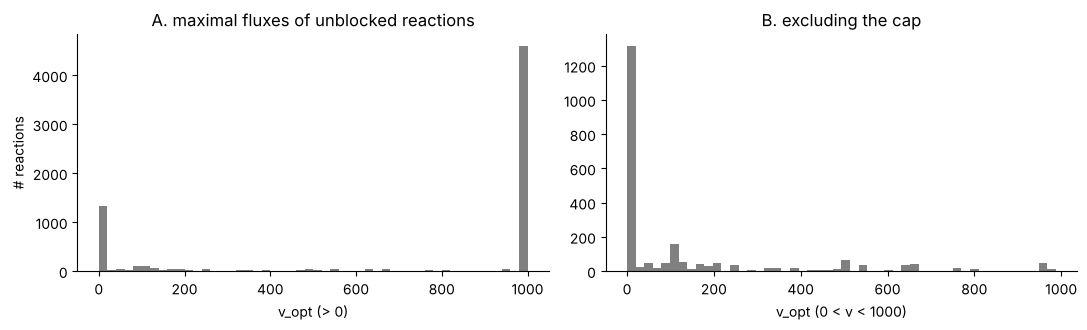

,cached v_opt,our v_opt,match
UGT1A10r_pos,636.9278,636.9278,True
GAO1g_pos,250.0000,250.0000,True
G14T20g_pos,38.4615,38.4615,True
FAOXC164x_pos,16.0000,16.0000,True
PPItx_pos,500.0000,500.0000,True
5ADTSTSTERONEGLCte_pos,549.0810,549.0810,True
PGM_neg,1000.0000,1000.0000,True
PDHm_pos,1000.0000,1000.0000,True


In [8]:
vopt = pd.Series(json.load(open(RES / "COMPASS/RECON2_mat/default-media/preprocess.json"))).reindex(recon.ids)
print(f"reactions with a cached v_opt   : {vopt.notna().sum():,} of {len(vopt):,}")
print(f"blocked (v_opt = 0)             : {(vopt == 0).sum():,}  ({(vopt == 0).mean():.0%})   -> Compass writes penalty 0 for these")
print(f"v_opt exactly at the 1000 cap   : {(vopt == 1000).sum():,}  ({(vopt == 1000).mean():.0%})")
print(f"all-zero rows in reactions.tsv  : {(pen_repo == 0).all(axis=1).sum():,}   equal to the blocked set: {((pen_repo == 0).all(axis=1) == (vopt == 0)).all()}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(vopt[vopt > 0], bins=50, color="grey"); ax[0].set_xlabel("v_opt (> 0)"); ax[0].set_ylabel("# reactions"); ax[0].set_title("A. maximal fluxes of unblocked reactions")
ax[1].hist(vopt[(vopt > 0) & (vopt < 1000)], bins=50, color="grey"); ax[1].set_xlabel("v_opt (0 < v < 1000)"); ax[1].set_title("B. excluding the cap")
plt.tight_layout(); plt.show()

# verify Algorithm 1 on a few reactions with non-trivial v_opt (not 0, not the cap)
sample = vopt[(vopt > 0) & (vopt < 1000)].sample(6, random_state=0).index.tolist() + ["PGM_neg", "PDHm_pos"]
chk = pd.DataFrame({"cached v_opt": vopt[sample], "our v_opt": [max_flux(recon, r) for r in sample]})
chk["match"] = np.isclose(chk["cached v_opt"], chk["our v_opt"]); chk

**How to read it.** About a third of the 10,211 unidirectional reactions cannot carry flux in this medium (blocked), and **almost half of the unblocked ones have `v_opt` exactly at the model's artificial cap of 1000** — their "maximal flux" is set by the cap, not by nutrients (cf. the paper's own caveat that only 2-cycles are excluded, so longer futile cycles can inflate fluxes: **[Paper, STAR Methods, constraint (iii)]**). **[Inference]** Consequently ω·v_opt = 950 is a large, somewhat arbitrary flux for these reactions. Our recomputed `v_opt` equals the cached one, so Algorithm 1 is reproduced.

## Part C — Stage 1 on the real data: genes → reaction expression → penalties
### C.1 Parse the gene rules and look at a few
Recon2 gene rules are strings such as `(x(5)) & (x(6)) | (x(7))` where `x(n)` is the *n*-th model gene. Mouse cells need mouse symbols: the repo maps each model gene to a mouse symbol (`uniqueMouseGeneSymbol.json`, via MGI HomoloGene) plus alternative symbols; genes without a mouse ortholog are blank **[Repo, importMATLAB.py, geneSymbols.py]**.

Operator precedence: `&` binds tighter than `|`; chains of the same operator are flattened; parenthesised groups stay nested (this matters for the mean in AND).

In [9]:
gene_ids = mj("genes"); gtx = json.load(open(MODEL_DIR / "non2uniqueEntrez.json"))
sym     = json.load(open(MODEL_DIR / "uniqueMouseGeneSymbol.json")); sym_all = json.load(open(MODEL_DIR / "uniqueMouseGeneSymbol_all.json"))
g_name  = [sym[gtx[i] - 1].upper() for i in range(len(gene_ids))]                   # primary mouse symbol per model gene ('' = no ortholog)
g_alt   = [[a.upper() for a in sym_all[gtx[i] - 1]] for i in range(len(gene_ids))]  # alternative symbols
print(f"model genes: {len(gene_ids):,}   with NO mouse symbol: {sum(n == '' for n in g_name):,}")

TOKEN = re.compile(r"x\(\d+\)|\(|\)|\||&")
def parse_rule(rule):
    """'(x(1)) | (x(2) & x(3))'  ->  ('or', [('gene',0), ('and', [('gene',1), ('gene',2)])])"""
    toks, pos = TOKEN.findall(rule), 0
    def peek(): return toks[pos] if pos < len(toks) else None
    def eat():
        nonlocal pos; t = toks[pos]; pos += 1; return t
    def p_or():
        items = [p_and()]
        while peek() == "|": eat(); items.append(p_and())
        return items[0] if len(items) == 1 else ("or", items)
    def p_and():
        items = [p_atom()]
        while peek() == "&": eat(); items.append(p_atom())
        return items[0] if len(items) == 1 else ("and", items)
    def p_atom():
        t = eat()
        if t == "(":
            node = p_or(); eat(); return node
        return ("gene", int(t[2:-1]) - 1)
    node = p_or(); assert pos == len(toks); return node

def pretty(node):
    if node[0] == "gene": return g_name[node[1]] or "<no mouse ortholog>"
    return "(" + (" AND " if node[0] == "and" else " OR ").join(pretty(c) for c in node[1]) + ")"

trees = {r: parse_rule(t) for r, t in zip(rxns, rules_txt) if t}
for r in ["PGM", "LDH_L", "PDHm", "ARGN"]:
    print(f"{r:6s}: {pretty(trees[r])}")
print(f"\nreactions with a gene rule: {len(trees):,} of {len(rxns):,};  without: {len(rxns) - len(trees):,}")

model genes: 2,140   with NO mouse symbol: 337
PGM   : (BPGM OR PGAM1 OR PGAM2 OR PGAM2 OR BPGM)
LDH_L : ((LDHB AND LDHA) OR <no mouse ortholog> OR LDHC OR LDHA OR LDHC OR UEVLD OR LDHB OR LDHAL6B)
PDHm  : (((DLD AND PDHX) AND (<no mouse ortholog> AND PDHB) AND DLAT) OR ((DLD AND PDHX) AND (PDHA1 AND PDHB) AND DLAT))
ARGN  : (ARG1 OR ARG2)

reactions with a gene rule: 4,821 of 7,440;  without: 2,619


**Three things to notice in these rules** (they are properties of the model + mouse mapping, and they change the numbers):
1. **Repeated genes.** PGM's rule lists `BPGM` and `PGAM2` *twice* (several human model genes map to the same mouse symbol). With the paper's setting `--isoform-summing legacy` the OR **sums both copies**, i.e. counts those genes' expression twice; the repo's current CLI default `remove-summing` drops the repeats **[Repo: `Association.remove_isoform_summing`, `main.py`; paper command in `postprocessing.ipynb`]**. We keep `legacy` here to match the paper.
2. **Missing orthologs inside AND.** PDHm contains `<no mouse ortholog>` inside an AND-group. With the *mean* AND-function a missing gene is counted as **0 but stays in the denominator**, so it pulls the whole complex's expression down for every cell **[Repo `mean_nan_zero`]**. **[Inference]** This lowers the reaction's absolute support but not necessarily the Th17p-vs-Th17n *comparison*.
3. **Complexes vs isozymes.** AND = mean (not min), OR = sum: a complex needs all subunits (averaged), isozymes add up **[Paper, "From gene expression to reaction expression"]**.

### C.2 Reaction expression for all 290 Th17 cells
Gene lookup: primary symbol first; else the mean over alternative symbols found; else `NaN` **[Repo, Gene.eval_expression]**. OR = sum of children ignoring NaN; AND = mean with NaN counted as 0 (`--and-function mean`, the paper's setting). A reaction without a rule gets 0. Finally `R = log2(x + 1)`.

In [10]:
expr = pd.read_csv(DATA / "Th17/linear_gene_expression_matrix.tsv", sep="\t", index_col=0)
expr.index = expr.index.astype(str).str.upper()
X, row_of, n_cells = expr.to_numpy(float), {g: i for i, g in enumerate(expr.index)}, expr.shape[1]
assert list(expr.columns) == list(pen_repo.columns) == list(meta_cells.index)

_cache = {}
def gene_vec(i):
    """expression of model gene i across cells (NaN if the gene is blank or absent from the data)"""
    if i not in _cache:
        nm = g_name[i]
        if nm == "": v = np.full(n_cells, np.nan)
        elif nm in row_of: v = X[row_of[nm]]
        else:
            found = [X[row_of[a]] for a in g_alt[i] if a in row_of]
            v = np.mean(found, axis=0) if found else np.full(n_cells, np.nan)
        _cache[i] = v
    return _cache[i]

R_lin = {}
for r, t in trees.items():
    v = eval_rule(t, gene_vec, "mean")                       # linear-scale reaction expression for all cells
    R_lin[r] = np.where(np.isnan(v), 0.0, v)                 # NaN (nothing measurable) -> 0
R = pd.DataFrame({r: np.log2(R_lin[r] + 1) if r in R_lin else np.zeros(n_cells) for r in rxns}, index=expr.columns).T   # reactions x cells, log2(x+1)

print(f"reaction-expression matrix: {R.shape[0]:,} reactions x {R.shape[1]} cells")
print(f"reactions with R = 0 in EVERY cell: {(R.max(axis=1) == 0).sum():,}  (no rule, or none of its genes measured/orthologous)")
print(f"reactions with a gene rule and R > 0 somewhere: {((R.max(axis=1) > 0) & R.index.isin(list(trees))).sum():,}")

reaction-expression matrix: 7,440 reactions x 290 cells
reactions with R = 0 in EVERY cell: 4,367  (no rule, or none of its genes measured/orthologous)
reactions with a gene rule and R > 0 somewhere: 3,073


### C.3 Smoothing with neighbours and the penalty formula
Compass mixes each cell's reaction expression with the mean of its *k* = 10 nearest neighbours' (kNN in the 20-PC space of all genes) and converts to penalties:
`penalty = (1 − λ) / (1 + R_cell) + λ / (1 + R_neighbourhood)`, λ = 0.25 **[Paper, "Information sharing…" & Alg. 2; Repo penalties.py `eval_reaction_penalties_shared`]**. Below we reproduce this and then compare with the repo's own function.

In [11]:
LAMBDA, K, PCA_SEED = 0.25, 10, 1337
emb = PCA(n_components=20, random_state=PCA_SEED).fit_transform(np.log2(expr + 1).T.to_numpy())
knn = NearestNeighbors(n_neighbors=K).fit(emb).kneighbors(return_distance=False)       # neighbours exclude the cell itself
W = np.zeros((n_cells, n_cells)); W[np.repeat(np.arange(n_cells), K), knn.ravel()] = 1.0 / K     # each cell: mean of its 10 neighbours

R_nb = pd.DataFrame(W @ R.to_numpy().T, index=expr.columns, columns=R.index).T          # neighbourhood reaction expression
P_cell   = 1.0 / (1.0 + R)                                                               # lambda = 0: no smoothing
P_stage1 = (1 - LAMBDA) / (1 + R) + LAMBDA / (1 + R_nb)                                  # Compass stage-1 penalty (base reactions x cells)
print("stage-1 penalty range:", round(P_stage1.values.min(), 3), "-", round(P_stage1.values.max(), 3), "(1.0 = no expression support)")

# map base reactions -> unidirectional ids (forward and backward copies share the same penalty)
base = pd.Series([r[:-4] if r.endswith(("_pos", "_neg")) else r for r in recon.ids], index=recon.ids)
pen1 = P_stage1.loc[base.values].set_axis(recon.ids)

stage-1 penalty range: 0.052 - 1.0 (1.0 = no expression support)


In [12]:
# OPTIONAL AUDIT: compare with the repo's own stage-1 code (needs the repo's Python dependencies; skipped if they are missing)
try:
    sys.path.insert(0, str(REPO))
    from compass import models as cmodels
    from compass.compass import penalties as cpen
    cm = cmodels.init_model("RECON2_mat", species="mus_musculus", exchange_limit=1.0, media="default-media", isoform_summing="legacy")
    cells30 = list(expr.columns[::10])
    ref = pd.concat([cpen.eval_reaction_expression_single(cm, expr[c], "mean") for c in cells30], axis=1)
    mine = R.loc[[r[:-4] if r.endswith(("_pos", "_neg")) else r for r in ref.index]].set_axis(ref.index)[cells30]
    print(f"repo vs ours (reaction expression, {len(cells30)} cells x {len(ref):,} reactions): max |difference| = {np.abs(mine.values - ref.values).max():.2e}")
except Exception as e:
    print("audit skipped (repo package not importable here):", type(e).__name__, "-", str(e)[:100])

repo vs ours (reaction expression, 29 cells x 10,211 reactions): max |difference| = 1.78e-14


**What this audit means.** A difference of ~1e-14 means our gene-rule evaluation reproduces the repo's code exactly — for *this* data, model and settings. (The audit is optional and needs the repo's dependencies installed; Compass itself is not run.)

### C.4 What smoothing does, and which reactions even have expression support

unidirectional reactions: 10,211
  with a gene rule             : 6,137
  without a gene rule          : 4,074   -> stage-1 penalty is exactly 1 in every cell
  rule exists but no signal    : 2,115   -> genes unmeasured / no mouse ortholog / zero expression

median SD(smoothed) / SD(unsmoothed) across reactions: 0.75
arginase genes present in the expression matrix? {'ARG1': False, 'ARG2': False}  | polyamine genes ODC1, SAT1, ASS1 present: {'ODC1': True, 'SAT1': True, 'ASS1': True}


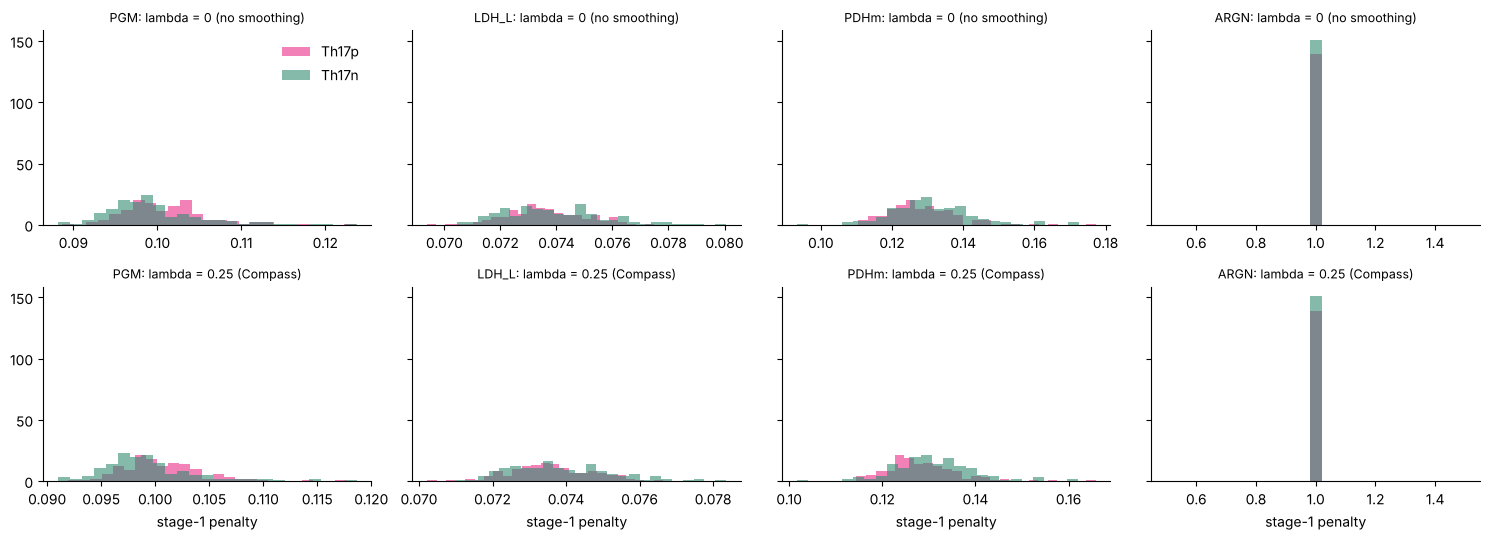

In [13]:
has_rule  = base.isin(list(trees))
no_signal = (R.max(axis=1) == 0).reindex(base.values).to_numpy()
print(f"unidirectional reactions: {len(recon.ids):,}")
print(f"  with a gene rule             : {has_rule.sum():,}")
print(f"  without a gene rule          : {(~has_rule).sum():,}   -> stage-1 penalty is exactly 1 in every cell")
print(f"  rule exists but no signal    : {(has_rule.to_numpy() & no_signal).sum():,}   -> genes unmeasured / no mouse ortholog / zero expression")

# smoothing shrinks cell-to-cell spread (noise) but keeps group differences
ratio = (P_stage1.std(axis=1) / P_cell.std(axis=1)).replace([np.inf, -np.inf], np.nan).dropna()
print(f"\nmedian SD(smoothed) / SD(unsmoothed) across reactions: {ratio.median():.2f}")

print("arginase genes present in the expression matrix?", {g: g in expr.index for g in ["ARG1", "ARG2"]}, " | polyamine genes ODC1, SAT1, ASS1 present:", {g: g in expr.index for g in ["ODC1", "SAT1", "ASS1"]})
ex = ["PGM", "LDH_L", "PDHm", "ARGN"]
fig, ax = plt.subplots(2, 4, figsize=(15, 5.5), sharey="row")
for j, r in enumerate(ex):
    for i, (nm, P) in enumerate([("lambda = 0 (no smoothing)", P_cell), (f"lambda = {LAMBDA} (Compass)", P_stage1)]):
        for g, c in PAL.items():
            ax[i, j].hist(P.loc[r][meta_cells.cell_type == g], bins=25, alpha=.6, color=c, label=g)
        ax[i, j].set_title(f"{r}: {nm}", fontsize=9)
ax[0, 0].legend(frameon=False); [a.set_xlabel("stage-1 penalty") for a in ax[1]]
plt.tight_layout(); plt.show()

**How to read it.** (1) About 40 % of unidirectional reactions have **no gene rule** — their stage-1 penalty is the same maximum in every cell, so any variation in their final score is *inherited from the network* (Part D). (2) Smoothing narrows the spread within each group (second row vs first), which reduces single-cell noise but also makes neighbours — all from the same condition (Notebook 1, §3.4) — more alike. (3) For PGM, LDH_L and PDHm the Th17p and Th17n penalty distributions overlap heavily — consistent with the modest effect sizes (|Cohen's d| ≈ 0.4–0.6) in Notebook 1. (4) **ARGN (arginase) has penalty 1 in every cell**: its genes are not in this expression matrix at all (check below), yet arginase is one of the reactions the paper highlights as differentially active (Notebook 1, Fig 2C). Its score therefore comes *entirely* from the surrounding network.

## Part D — Stage 2: re-solve real Compass LPs and compare with the repo's `reactions.tsv`
For a chosen reaction and cell we solve Algorithm 2's LP on the **full Recon2 network** (10,211 variables, 5,063 constraints) with SciPy's HiGHS: minimise `Σ penalty_i · v_i` subject to `S·v = 0`, bounds, reverse blocked, `v_r ≥ 0.95 · v_opt` (cached). The objective uses the stage-1 penalties from Part C for **all** reactions (exchange reactions included, penalty 1 — see `compass_reactions` in `algorithm.py` **[Repo]**). If our number equals the repo's, we have independently reproduced a Compass score.

In [14]:
test_rxns  = ["PGM_neg", "LDH_L_neg", "PDHm_pos", "TPI_neg", "AKGDm_pos", "CK_pos", "ARGN_pos", "C160CPT1_pos"]
test_cells = [meta_cells.index[meta_cells.cell_type == "Th17p"][0], meta_cells.index[meta_cells.cell_type == "Th17n"][0], meta_cells.index[150]]

rows, t0 = [], time.time()
for cell in test_cells:
    c = pen1[cell].reindex(recon.ids).to_numpy()
    for r in test_rxns:
        mine, _ = compass_penalty(recon, r, c, vopt[r])
        rows.append((cell, meta_cells.cell_type[cell], r, mine, pen_repo.loc[r, cell]))
cmp_ = pd.DataFrame(rows, columns=["cell", "group", "reaction", "our LP (HiGHS)", "repo reactions.tsv"])
cmp_["relative difference"] = (cmp_["our LP (HiGHS)"] - cmp_["repo reactions.tsv"]).abs() / cmp_["repo reactions.tsv"].abs()
print(f"{len(cmp_)} LPs solved in {time.time() - t0:.0f} s  |  max relative difference vs the repo's output: {cmp_['relative difference'].max():.1e}")
assert cmp_["relative difference"].max() < 1e-6, "mismatch with the repo output!"
cmp_.head(10)

24 LPs solved in 4 s  |  max relative difference vs the repo's output: 9.9e-16


,cell,group,reaction,our LP (HiGHS),repo reactions.tsv,relative difference
0,SRR2921282,Th17p,PGM_neg,3430.9625,3430.9625,0.0000e+00
1,SRR2921282,Th17p,LDH_L_neg,3327.3986,3327.3986,4.1000e-16
2,SRR2921282,Th17p,PDHm_pos,8464.8933,8464.8933,8.5955e-16
3,SRR2921282,Th17p,TPI_neg,10470.8741,10470.8741,6.9488e-16
4,SRR2921282,Th17p,AKGDm_pos,13684.5592,13684.5592,5.3169e-16
5,SRR2921282,Th17p,CK_pos,3317.0455,3317.0455,1.3709e-16
6,SRR2921282,Th17p,ARGN_pos,23205.6734,23205.6734,4.7031e-16
7,SRR2921282,Th17p,C160CPT1_pos,2932.1818,2932.1818,0.0000e+00
8,SRR2921562,Th17n,PGM_neg,3596.9162,3596.9162,0.0000e+00
9,SRR2921562,Th17n,LDH_L_neg,3275.8641,3275.8641,0.0000e+00


**What this proves.** Our open-source re-implementation — gene rules → penalties → LP — returns the same numbers as the repo's Gurobi-based Compass run (differences ≈ 1e-16, i.e. rounding). So everything in Parts A–D is *the* algorithm, not an approximation, **for this model, medium and parameter set**. Compass's real cost is only scale: 10,211 LPs × 290 cells (the repo notes ≈ 30 min per cell on one core). Each LP here takes a fraction of a second.

### D.1 Anatomy of one score: what is the "cheapest balanced flux pattern"?
Take `PGM_neg` (phosphoglycerate mutase) in one Th17p cell. Which reactions carry flux, and where does the penalty come from?

In [15]:
cell, rid = test_cells[0], "PGM_neg"
c = pen1[cell].reindex(recon.ids).to_numpy()
val, flux = compass_penalty(recon, rid, c, vopt[rid])
rxn_md = pd.read_csv(DATA / "RECON2/reaction_metadata.csv", index_col=0)
used = flux[flux > 1e-9]
tab = pd.DataFrame({"flux": used, "penalty": pd.Series(c, index=recon.ids)[used.index]})
tab["cost = flux x penalty"] = tab.flux * tab.penalty
tab["has gene rule"] = [base[r] in trees for r in tab.index]
tab["name"] = [rxn_md.reaction_name.get(base[r], "")[:45] for r in tab.index]
tab = tab.sort_values("cost = flux x penalty", ascending=False)
print(f"{rid} in {cell}: total penalty {val:,.1f} = {rid}'s own cost {tab.loc[rid, 'cost = flux x penalty']:.1f} + {len(tab)-1} other reactions carrying flux")
print(f"share of the total that comes from reactions WITHOUT a gene rule (penalty fixed at 1): {tab.loc[~tab['has gene rule'], 'cost = flux x penalty'].sum() / val:.0%}")
tab.head(10)

PGM_neg in SRR2921282: total penalty 3,431.0 = PGM_neg's own cost 93.2 + 20 other reactions carrying flux
share of the total that comes from reactions WITHOUT a gene rule (penalty fixed at 1): 69%


,flux,penalty,cost = flux x penalty,has gene rule,name
EX_h(e)_pos,950.0,1.0000,950.0000,False,exchange reaction for proton
EX_lac_L(e)_pos,950.0,1.0000,950.0000,False,L-Lactate exchange
EX_man(e)_neg,474.0,1.0000,474.0000,False,exchange reaction for D-Mannose
L_LACt2r_neg,950.0,0.1804,171.3388,True,L-lactate reversible transport via proton sym
DPGase_pos,950.0,0.0981,93.2236,True,Diphosphoglycerate phosphatase
DPGM_pos,950.0,0.0981,93.2236,True,Diphosphoglyceromutase
PGM_neg,950.0,0.0981,93.2236,True,phosphoglycerate mutase
MAN6PI_pos,474.0,0.1725,81.7547,True,mannose-6-phosphate isomerase
MANt1r_pos,474.0,0.1565,74.1721,True,mannose transport (uniport)
ENO_pos,950.0,0.0739,70.2118,True,enolase


**How to read it.** Compass does not "measure PGM". It finds the cheapest steady-state flux pattern in which PGM runs at 950, and reports that pattern's cost. Notice (i) the pattern includes **exchange reactions** (the model takes up / secretes metabolites to balance the books), whose penalty is fixed at 1 because they have no gene rule; (ii) the genuinely expression-dependent reactions (PGM and its neighbours, penalty ≈ 0.1 when well expressed) contribute a *minority* of the total. **[Inference from this one example — check on more reactions before generalising]**: a large, cell-independent baseline plus a small expression-dependent part explains why raw penalties are in the thousands with only a few-percent spread between cells (see D.2).

### D.2 How much of the final penalty is signal?

coefficient of variation of the final penalty across the 290 cells (non-blocked reactions): median 3.8%, 90th percentile 29.6%


informative reactions WITHOUT a gene rule (variation is purely inherited from the network): 2,071


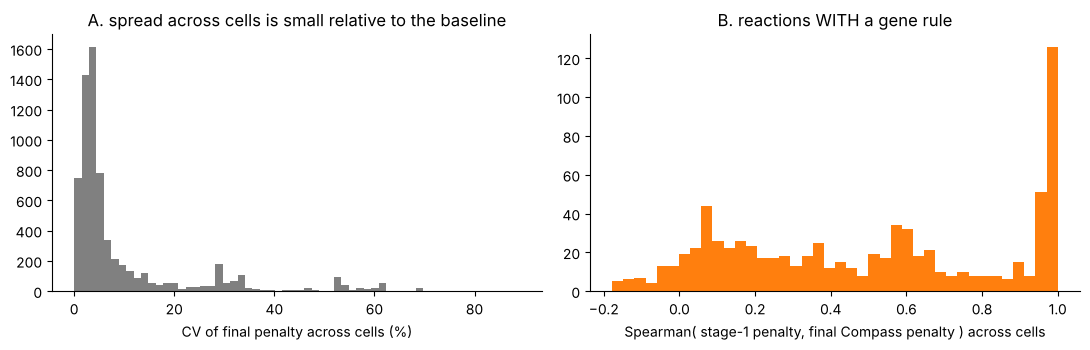

median Spearman over reactions with a rule: 0.51


In [16]:
keep = ~((pen_repo == 0).all(axis=1))                                    # drop blocked rows
cv = (pen_repo[keep].std(axis=1) / pen_repo[keep].mean(axis=1))
print(f"coefficient of variation of the final penalty across the 290 cells (non-blocked reactions): median {cv.median():.1%}, 90th percentile {cv.quantile(.9):.1%}")

# do final penalties follow the stage-1 (expression-based) penalty of the SAME reaction across cells?
rows = []
for r in pen_repo.index[keep][::4]:                                       # every 4th reaction, for speed
    if pen1.loc[r].std() > 1e-9 and pen_repo.loc[r].std() > 1e-9:
        rows.append((r, has_rule[r], stats.spearmanr(pen1.loc[r], pen_repo.loc[r])[0]))
cor = pd.DataFrame(rows, columns=["reaction", "has_rule", "spearman"]).dropna()
no_rule_informative = (~has_rule[keep] & (pen_repo[keep].max(axis=1) - pen_repo[keep].min(axis=1) > 1e-3)).sum()
print(f"informative reactions WITHOUT a gene rule (variation is purely inherited from the network): {no_rule_informative:,}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(cv * 100, bins=60, color="grey"); ax[0].set_xlabel("CV of final penalty across cells (%)"); ax[0].set_title("A. spread across cells is small relative to the baseline")
ax[1].hist(cor.spearman, bins=40, color="tab:orange"); ax[1].set_xlabel("Spearman( stage-1 penalty, final Compass penalty ) across cells"); ax[1].set_title("B. reactions WITH a gene rule")
plt.tight_layout(); plt.show()
print(f"median Spearman over reactions with a rule: {cor.spearman.median():.2f}")

**How to read it.** (A) The final penalty varies by only a few percent between cells, on top of a large shared baseline. (B) For reactions that *have* a gene rule, the final score is usually — not always — positively related to the reaction's own stage-1 penalty: the network adds context rather than replacing the gene signal. Reactions *without* a rule still vary across cells (counted above), purely through the network — which is Compass's selling point and also what makes the score hard to interpret biologically: **a "significant" reaction without its own enzyme gene reflects its neighbours' expression** **[Inference]**.

## Part E — What you should now be able to explain
1. **Stage 0:** `v_opt` per reaction (expression-independent, cached; ≈ 1/3 blocked, ≈ 1/2 of the rest at the 1000 cap).
2. **Stage 1:** gene rule → reaction expression (OR = sum, AND = mean; reaction without rule = 0) → `log2(x+1)` → mix with the 10 nearest neighbours (λ = 0.25) → penalty `1/(1+R)`.
3. **Stage 2:** `min Σ pᵢ vᵢ  s.t.  S v = 0, bounds, v_r ≥ 0.95 v_r^opt` → one number per (reaction, cell); score = −log(1 + penalty), shifted.
4. **Interpretation:** a score is the cost of the cheapest *network-wide* way to run the reaction near its maximum, given this cell's transcriptome. It is **not** a flux measurement, and it depends on the medium, the cap, the model's gene rules, the mouse↔human gene mapping, and fixed parameters (ω, λ, k, AND-rule).

### Map: paper ↔ repo code
| Paper element | Where in the repo |
|---|---|
| Alg. 1 maximal fluxes | `compass/compass/algorithm.py::maximize_reaction`; cache `Resources/COMPASS/<model>/<media>/preprocess.json` |
| Gene rule → reaction expression | `models/MetabolicModel.py` (`Association.eval_expression`, `Gene.eval_expression`), `compass/penalties.py::eval_reaction_expression_single` |
| kNN smoothing & penalty | `compass/penalties.py::eval_reaction_penalties_shared`, `sample_weights_knn` |
| Alg. 2 LP (`ω = 0.95`) | `compass/algorithm.py::compass_reactions`; `compass/opt/gurobi.py::GurobiOptimizer.solve`; `BETA` in `globals.py` |
| Unidirectional split; exchange cap; medium | `MetabolicModel.make_unidirectional`; `limitExchangeReactions` (`EXCHANGE_LIMIT = 1.0`); `load_media` |
| Alg. 3 scaling, meta-reactions, tests | `docs/notebooks/compass_analysis.py`, `docs/notebooks/postprocessing.ipynb` |